
# Предсказание оттока клиентов банка

## 1. Постановка задачи

### Бизнес-постановка

Цель проекта — выявлять клиентов, которые с высокой вероятностью прекратят обслуживание в банке.

Прогнозирование оттока позволит банку заранее предлагать таким клиентам персональные условия и снижать затраты на привлечение новых клиентов.

### ML-постановка

Задача бинарной классификации.

Целевая переменная `Exited`:
- `0` — клиент остался в банке;
- `1` — клиент ушёл из банка.

Модель должна оценивать вероятность ухода клиента на основе его финансовых и демографических характеристик.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Среда настроена успешно!")


Среда настроена успешно!


In [2]:

url = "https://raw.githubusercontent.com/zunicd/Bank-Churn-Prediction/master/Resources/Churn_Modelling.csv"

df = pd.read_csv(url)

display(df.head())
print("Размер датасета:", df.shape)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Размер датасета: (10000, 14)


In [3]:
# Размер датасета
print("Размер:", df.shape)

# Названия столбцов и их типы
df.info()

# Первые 5 строк
display(df.head())

Размер: (10000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
# Основные статистики по числовым признакам
display(df.describe())

# Проверка пропущенных значений
display(df.isnull().sum())

# Распределение целевой переменной
display(df["Exited"].value_counts(normalize=True) * 100)

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


### Первичные выводы по данным

В ходе предварительного анализа были получены следующие результаты:

1. Датасет содержит 10 000 наблюдений и 14 столбцов, включая целевую переменную `Exited`.

2. Пропущенные значения отсутствуют, поэтому на данном этапе не требуется применение методов заполнения пропусков или удаления неполных наблюдений.

3. В наборе данных присутствуют как числовые, так и категориальные признаки, соответственно столбцы `Geography` и `Gender` потребуется изменить.

4. Признаки `RowNumber`, `CustomerId` и `Surname` не будут использоваться так как являются просто идентификаторами человека.

5. Наблюдается дисбаланс целевой переменной: 79,63% клиентов остались в банке, а 20,37% прекратили обслуживание. Следовательно, Accuracy нецелесообразно использовать в качестве единственной метрики качества.

6. Возраст клиентов варьируется от 18 до 92 лет, а баланс счёта — от 0 до 250 898,09. В дальнейшем необходимо исследовать распределения признаков и проверить наличие выбросов.



## 2. Выбор метрик качества

В качестве основной метрики выбрана **ROC-AUC**, поскольку она оценивает способность модели различать клиентов, которые уйдут и останутся, независимо от конкретного порога классификации.

В качестве дополнительных метрик используются **Recall** и **Precision** для класса `Exited = 1`. Recall позволяет оценить долю обнаруженных уходящих клиентов, а Precision — долю действительно уходящих среди клиентов, которым банк потенциально предложит меры удержания.

Такой набор метрик позволяет учитывать как качество выявления клиентов с риском оттока, так и эффективность расходования бюджета на их удержание.


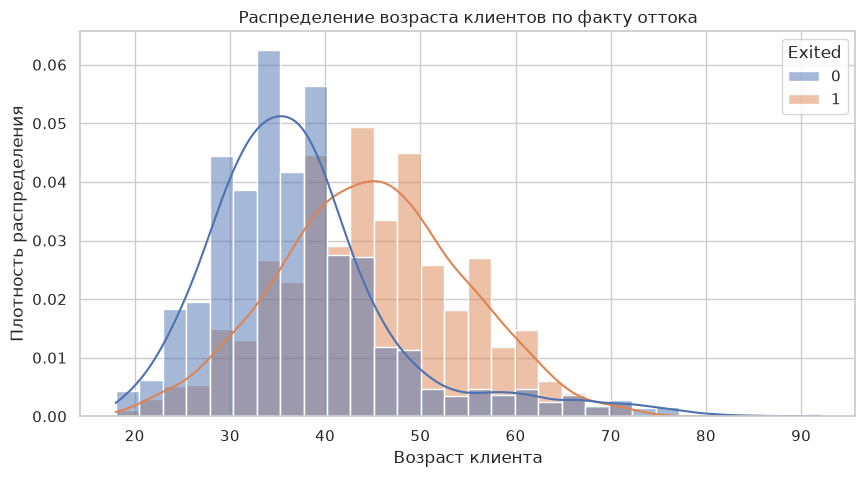

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Exited",
    bins=30,
    kde=True,
    stat="density",
    common_norm=False,
    alpha=0.5
)

plt.title("Распределение возраста клиентов по факту оттока")
plt.xlabel("Возраст клиента")
plt.ylabel("Плотность распределения")
plt.show()



### Анализ зависимости оттока от возраста

Распределения возраста клиентов, оставшихся в банке и прекративших обслуживание, заметно различаются.

Основная часть оставшихся клиентов сосредоточена в возрастном диапазоне примерно 30–40 лет, тогда как распределение ушедших клиентов смещено в сторону более старших возрастов, преимущественно 40–50 лет.

**Вывод:** возраст потенциально является информативным признаком для предсказания оттока. При обучении модели его следует сохранить.

При этом распределения имеют нелинейную форму, поэтому в дальнейшем имеет смысл проверить модели, способные учитывать нелинейные зависимости, например Random Forest или градиентный бустинг.


In [7]:
df.groupby("Exited")["Age"].agg(["mean", "median", "std"]).round(2)

,mean,median,std
Exited,,,
0,37.41,36.0,10.13
1,44.84,45.0,9.76



Дополнительный статистический анализ подтверждает различия между группами:

- Средний возраст оставшихся клиентов составляет 37,41 года.
- Средний возраст ушедших клиентов составляет 44,84 года.
- Разница средних возрастов составляет 7,43 года.
- Медианный возраст также различается: 36 лет против 45 лет.

Таким образом, возраст связан с фактом оттока клиентов и может быть важным предиктором для модели машинного обучения. Однако по результатам EDA нельзя утверждать, что именно возраст является причиной ухода клиента.


,churn_rate,count
AgeGroup,,
18–24,8.75,457
25–34,7.76,3222
35–44,17.66,3981
45–54,48.15,1458
55–64,49.83,600
65+,15.25,282


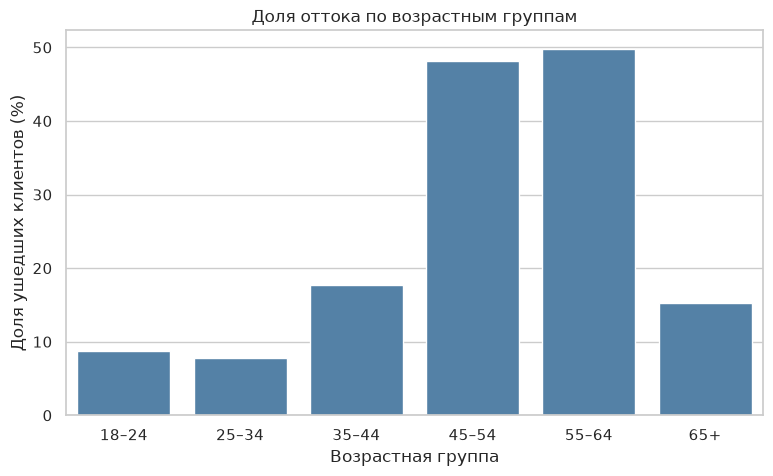

In [9]:

age_bins = [18, 25, 35, 45, 55, 65, 100]
age_labels = ["18–24", "25–34", "35–44", "45–54", "55–64", "65+"]

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

churn_by_age = df.groupby("AgeGroup", observed=True)["Exited"].agg(
    churn_rate="mean",
    count="count"
)

churn_by_age["churn_rate"] *= 100

display(churn_by_age.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=churn_by_age.reset_index(),
    x="AgeGroup",
    y="churn_rate",
    color="steelblue"
)

plt.title("Доля оттока по возрастным группам")
plt.xlabel("Возрастная группа")
plt.ylabel("Доля ушедших клиентов (%)")
plt.show()



### Выводы по возрастным группам

Анализ доли оттока по возрастным группам выявил выраженную нелинейную зависимость между возрастом клиента и вероятностью прекращения обслуживания.

Наименьшая доля оттока наблюдается среди клиентов 25–34 лет (7,76%). В возрастных группах 45–54 и 55–64 лет этот показатель значительно выше — 48,15% и 49,83% соответственно.

При этом среди клиентов старше 65 лет доля оттока снижается до 15,25%. Однако данная группа относительно небольшая (282 наблюдения), поэтому оценку следует интерпретировать осторожно.

**Вывод:** возраст является потенциально информативным признаком, причём его связь с оттоком нелинейна.

Для дальнейшего моделирования целесообразно:
- Сохранить исходный числовой признак `Age`.
- Рассмотреть модели, способные учитывать нелинейные зависимости.
- При использовании линейных моделей проверить возможность создания дополнительных признаков на основе возрастных групп.


,churn_rate,count
Geography,,
France,16.15,5014
Germany,32.44,2509
Spain,16.67,2477


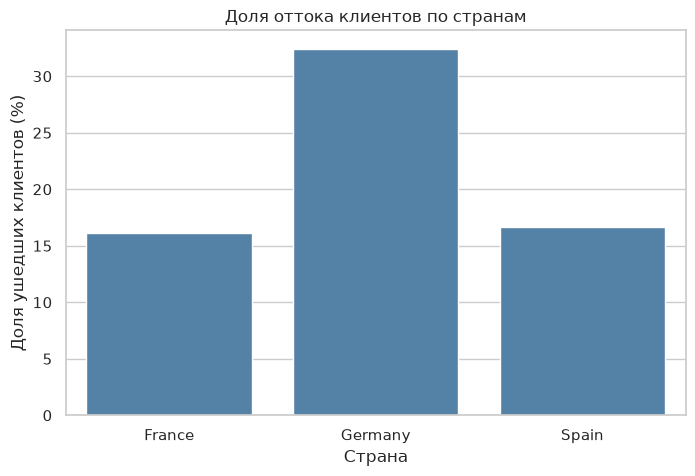

In [10]:

churn_by_country = (
    df.groupby("Geography")["Exited"]
    .agg(churn_rate="mean", count="count")
)

churn_by_country["churn_rate"] *= 100

display(churn_by_country.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=churn_by_country.reset_index(),
    x="Geography",
    y="churn_rate",
    color="steelblue"
)

plt.title("Доля оттока клиентов по странам")
plt.xlabel("Страна")
plt.ylabel("Доля ушедших клиентов (%)")
plt.show()



### Анализ зависимости оттока от страны проживания

Анализ признака `Geography` выявил существенные различия в доле оттока клиентов между странами.

- Во Франции доля оттока составляет приблизительно 16,15%.
- В Германии — 32,44%.
- В Испании — 16,67%.

Таким образом, доля оттока среди клиентов из Германии примерно в два раза выше, чем среди клиентов из Франции и Испании.

**Вывод:** страна проживания потенциально является информативным категориальным признаком для прогнозирования оттока.

При дальнейшем моделировании целесообразно сохранить `Geography` и применить One-Hot Encoding для моделей, требующих числового представления категориальных признаков.

При этом выявленная зависимость не доказывает, что страна проживания непосредственно влияет на решение клиента прекратить обслуживание.


,churn_rate,count
IsActiveMember,,
0,26.85,4849
1,14.27,5151


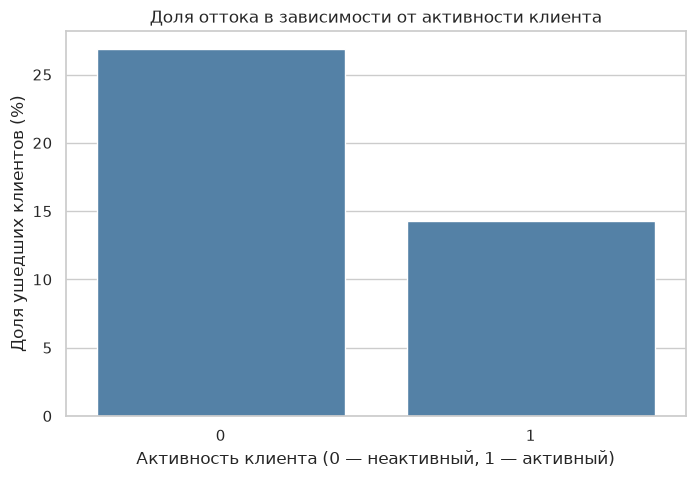

In [11]:

churn_by_activity = (
    df.groupby("IsActiveMember")["Exited"]
    .agg(churn_rate="mean", count="count")
)

churn_by_activity["churn_rate"] *= 100

display(churn_by_activity.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=churn_by_activity.reset_index(),
    x="IsActiveMember",
    y="churn_rate",
    color="steelblue"
)

plt.title("Доля оттока в зависимости от активности клиента")
plt.xlabel("Активность клиента (0 — неактивный, 1 — активный)")
plt.ylabel("Доля ушедших клиентов (%)")

plt.show()



### Анализ зависимости оттока от активности клиентов

Анализ признака `IsActiveMember` показал заметную связь между активностью клиента и фактом прекращения обслуживания.

Среди неактивных клиентов доля оттока составляет 26,85%, тогда как среди активных — 14,27%.

Таким образом, доля оттока неактивных клиентов примерно в 1,88 раза выше, чем активных.

**Вывод:** активность клиента является потенциально информативным признаком для прогнозирования оттока.

С точки зрения бизнеса неактивные клиенты могут представлять особый интерес для программ удержания. Однако выявленная зависимость не доказывает, что именно отсутствие активности является причиной ухода.

При построении модели целесообразно сохранить бинарный признак `IsActiveMember` без дополнительного кодирования.


,churn_rate,count
NumOfProducts,,
1,27.71,5084
2,7.58,4590
3,82.71,266
4,100.00,60


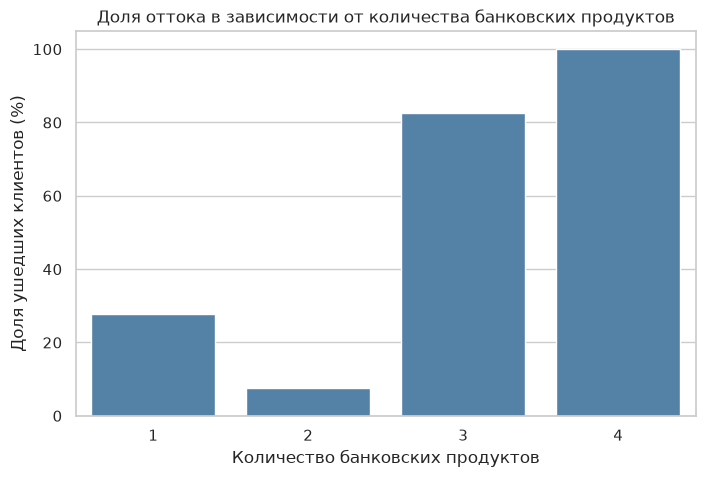

In [12]:

churn_by_products = (
    df.groupby("NumOfProducts")["Exited"]
    .agg(churn_rate="mean", count="count")
)

churn_by_products["churn_rate"] *= 100

display(churn_by_products.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=churn_by_products.reset_index(),
    x="NumOfProducts",
    y="churn_rate",
    color="steelblue"
)

plt.title("Доля оттока в зависимости от количества банковских продуктов")
plt.xlabel("Количество банковских продуктов")
plt.ylabel("Доля ушедших клиентов (%)")

plt.show()



### Анализ зависимости оттока от количества банковских продуктов

Анализ признака `NumOfProducts` показал выраженную нелинейную зависимость между количеством используемых банковских продуктов и долей оттока.

Наименьшая доля оттока наблюдается среди клиентов, использующих два банковских продукта (7,58%). Среди клиентов с одним продуктом этот показатель составляет 27,71%.

Неожиданно высокая доля оттока наблюдается среди клиентов с тремя (82,71%) и четырьмя (100%) продуктами.

Однако группы с тремя и четырьмя продуктами относительно малочисленны — 266 и 60 клиентов соответственно, поэтому к интерпретации этих результатов следует подходить осторожно.

**Вывод:** количество банковских продуктов потенциально является важным признаком для прогнозирования оттока, но его связь с целевой переменной немонотонна.

При дальнейшем моделировании рекомендуется:
- Сохранить признак `NumOfProducts`.
- Рассмотреть возможность представления количества продуктов как категориального признака.
- Использовать модели, способные учитывать нелинейные зависимости.
- Проверить, сохраняется ли выявленная закономерность на тестовой выборке.


In [13]:

financial_features = [
    "Balance",
    "CreditScore",
    "EstimatedSalary"
]

financial_stats = (
    df.groupby("Exited")[financial_features]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(financial_stats)


Balance                      CreditScore                 \
            mean     median       std        mean median     std   
Exited                                                             
0       72745.30   92072.68  62848.04      651.85  653.0   95.65   
1       91108.54  109349.29  58360.79      645.35  646.0  100.32   

       EstimatedSalary                       
                  mean     median       std  
Exited                                       
0             99738.39   99645.04  57405.59  
1            101465.68  102460.84  57912.42

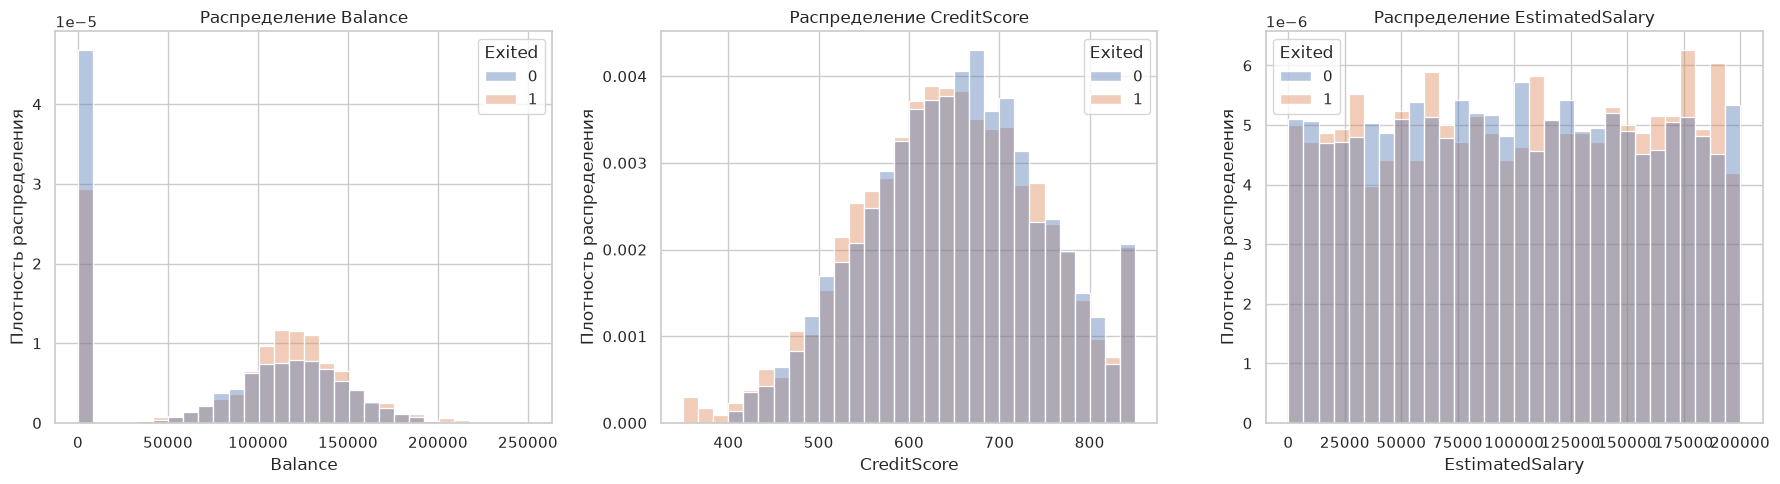

In [14]:

financial_features = [
    "Balance",
    "CreditScore",
    "EstimatedSalary"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, financial_features):
    sns.histplot(
        data=df,
        x=feature,
        hue="Exited",
        bins=30,
        stat="density",
        common_norm=False,
        alpha=0.4,
        ax=ax
    )

    ax.set_title(f"Распределение {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Плотность распределения")

plt.tight_layout()
plt.show()



### Анализ распределений финансовых признаков

**Balance**

Распределение баланса счёта характеризуется большим количеством нулевых значений и отдельной группой клиентов с положительным балансом.

Среди клиентов с положительным балансом наблюдается распределение, близкое к колоколообразному.

Это говорит о неоднородности признака. В дальнейшем можно рассмотреть создание дополнительного бинарного признака `HasZeroBalance`.

**CreditScore**

Распределения кредитных рейтингов ушедших и оставшихся клиентов существенно перекрываются. Это согласуется с ранее обнаруженным небольшим различием средних значений.

Следовательно, кредитный рейтинг, вероятно, имеет ограниченную самостоятельную прогностическую способность.

**EstimatedSalary**

Оценка дохода имеет приблизительно равномерное распределение. Существенных различий между распределениями ушедших и оставшихся клиентов визуально не наблюдается.

**Вывод:** среди рассмотренных финансовых характеристик наиболее интересным для дальнейшего исследования является `Balance`.

При этом признаки `CreditScore` и `EstimatedSalary` пока не следует исключать из модели, поскольку они могут оказаться полезными во взаимодействии с другими характеристиками клиентов.


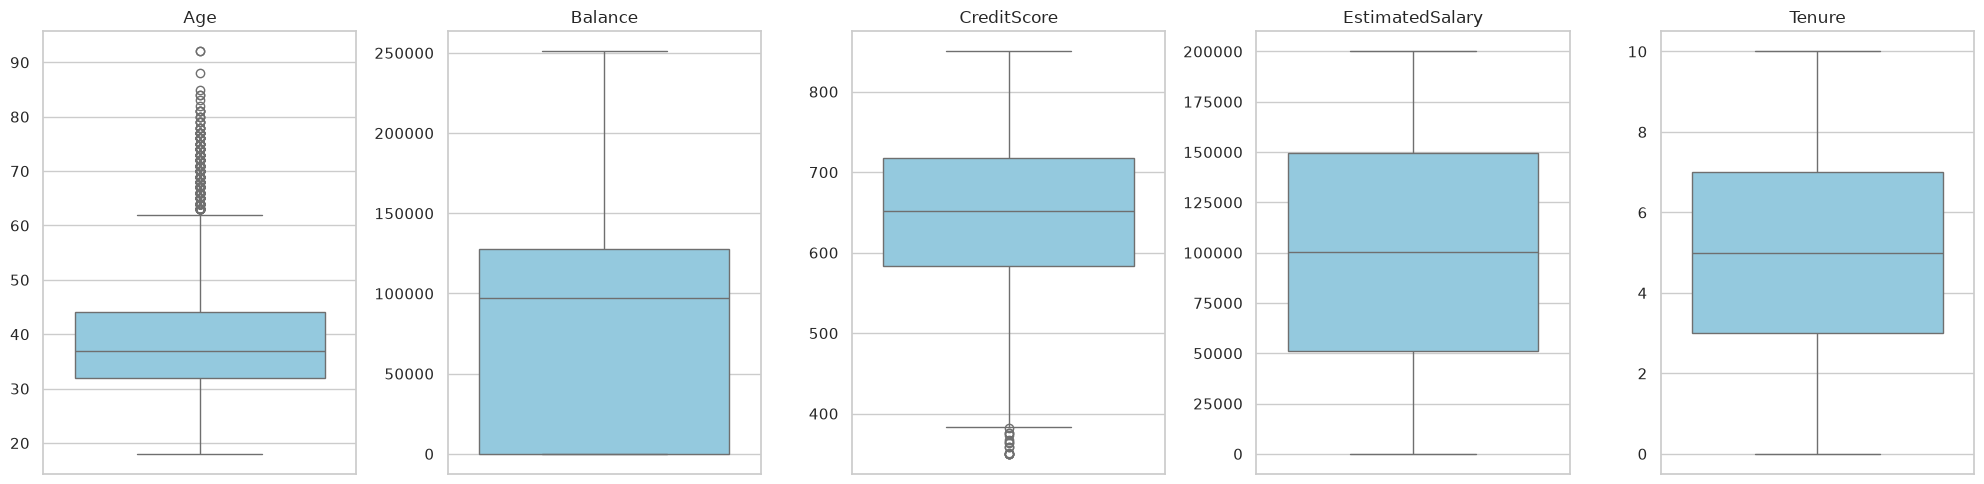

In [16]:

numeric_features = [
    "Age",
    "Balance",
    "CreditScore",
    "EstimatedSalary",
    "Tenure"
]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, feature in zip(axes, numeric_features):
    sns.boxplot(
        data=df,
        y=feature,
        ax=ax,
        color="skyblue"
    )

    ax.set_title(feature)
    ax.set_ylabel("")

plt.tight_layout()
plt.show()


### Анализ выбросов в числовых признаках

Для выявления потенциальных выбросов были построены диаграммы размаха (boxplot) для пяти числовых признаков.

В результате анализа установлено:

- **Age:** наблюдаются значения выше верхней границы диаграммы размаха (примерно 62 года). Эти значения могут соответствовать реальным клиентам старшего возраста.
- **CreditScore:** присутствуют отдельные низкие значения кредитного рейтинга, расположенные за пределами нижнего уса диаграммы.
- **Balance:** статистические выбросы по стандартному правилу 1,5 IQR не обнаружены. При этом распределение содержит большое количество нулевых балансов.
- **EstimatedSalary:** выраженных выбросов не обнаружено.
- **Tenure:** выбросов не обнаружено.

**Вывод:** потенциальные выбросы выявлены преимущественно в признаках `Age` и `CreditScore`.

Автоматическое удаление этих наблюдений нецелесообразно, поскольку они могут представлять реальные характеристики клиентов.

При дальнейшем моделировании рекомендуется сохранить исходные значения, а при использовании моделей, чувствительных к масштабу признаков и экстремальным значениям, рассмотреть применение подходящих методов масштабирования.